In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# loading cleaned dataset
df = pd.read_csv("D:\Sales & Revenue Analysis\Data\cleaned_superstore.csv")

# conveting order date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])

# checking dataset
print("Dataset Shape: ", df.shape)
df.head()

Dataset Shape:  (9994, 26)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Number,Year-Month,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,November,11,2016-11,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,November,11,2016-11,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,June,6,2016-06,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,October,10,2015-10,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,October,10,2015-10,11.25


In [7]:
# Calculating main business KPIs
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_quantity = df["Quantity"].sum()
total_customers = df["Customer ID"].nunique()

avg_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

# results

print("---------- Overall sales performance ----------")

print("\nTotal Revenue: ", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Total Customers:", total_customers)
print("Average Order Value:", round(avg_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")

---------- Overall sales performance ----------

Total Revenue:  2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Quantity Sold: 37873
Total Customers: 793
Average Order Value: 458.61
Profit Margin: 12.47 %


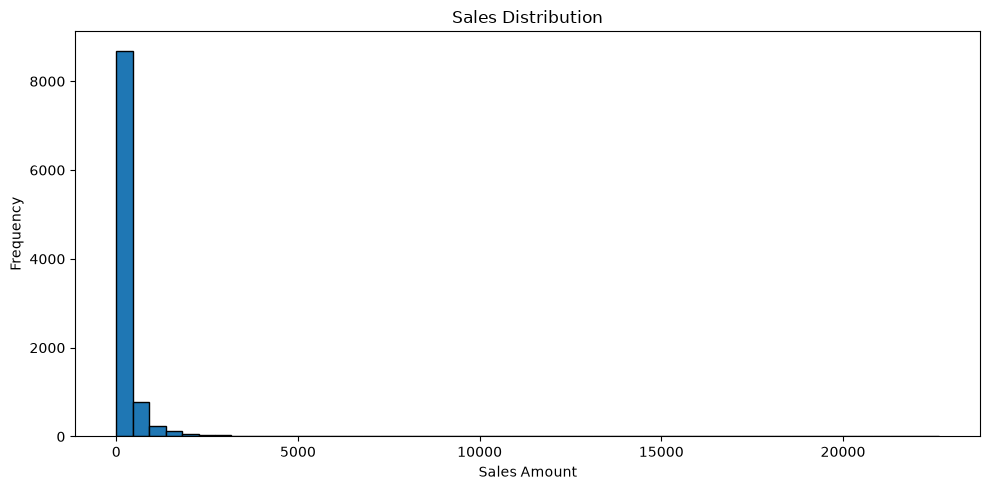

In [67]:
# Sales Distribution plot

plt.figure(figsize = (10, 5))
plt.hist(df["Sales"], bins = 50, edgecolor = "black")

plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\sales_distribution.png")

plt.show()

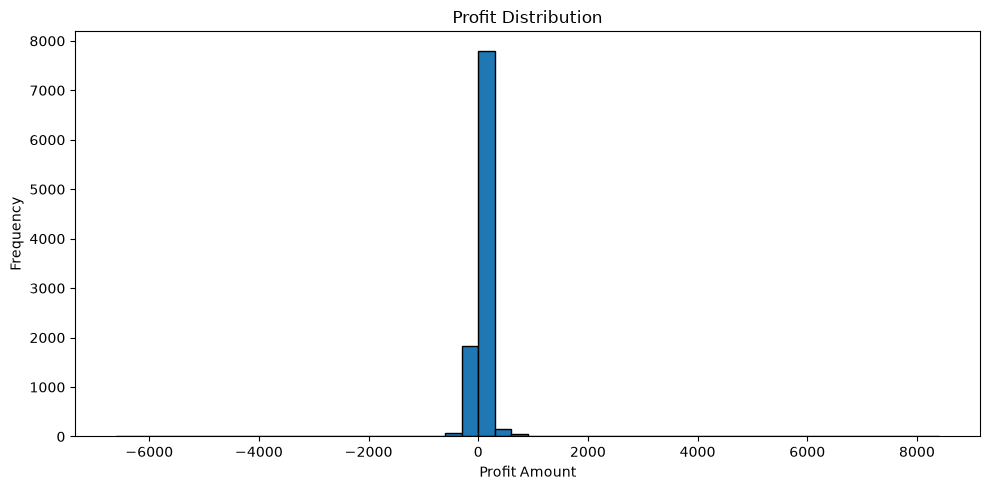

In [66]:
# Profit Distribution Plot

plt.figure(figsize = (10, 5))
plt.hist(df["Profit"], bins = 50, edgecolor = "black")

plt.title("Profit Distribution")
plt.xlabel("Profit Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\profit_distribution.png")

plt.show()

In [19]:
# Monnthly sales trend analysis

# grouping sales and profit by month
monthly_sales = (
    df.groupby("Year-Month")
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum")
    )
    .reset_index()
    .sort_values("Year-Month")
)
print(monthly_sales.head(12))

   Year-Month  Total_Sales  Total_Profit
0     2014-01   14236.8950     2450.1907
1     2014-02    4519.8920      862.3084
2     2014-03   55691.0090      498.7299
3     2014-04   28295.3450     3488.8352
4     2014-05   23648.2870     2738.7096
5     2014-06   34595.1276     4976.5244
6     2014-07   33946.3930     -841.4826
7     2014-08   27909.4685     5318.1050
8     2014-09   81777.3508     8328.0994
9     2014-10   31453.3930     3448.2573
10    2014-11   78628.7167     9292.1269
11    2014-12   69545.6205     8983.5699


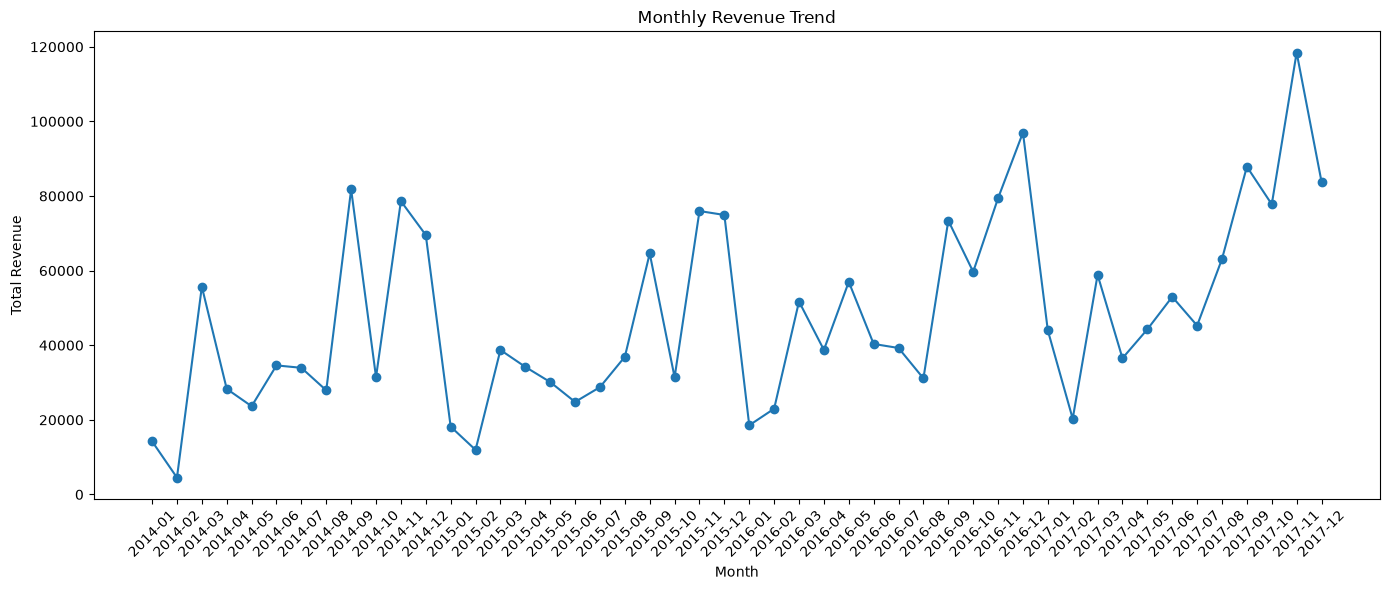

In [65]:
# Monthly Revenue Chart

plt.figure(figsize = (14, 6))

plt.plot (
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    marker = "o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation = 45)
plt.grid = True

plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\monthly_revenue.png")

plt.show()

In [24]:
# Yearly Sales Comparison

yearly_sales = (
    df.groupby("Year")
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum")
    )
    .reset_index()
)

print(yearly_sales)

   Year  Total_Sales  Total_Profit
0  2014  484247.4981    49543.9741
1  2015  470532.5090    61618.6037
2  2016  609205.5980    81795.1743
3  2017  733215.2552    93439.2696


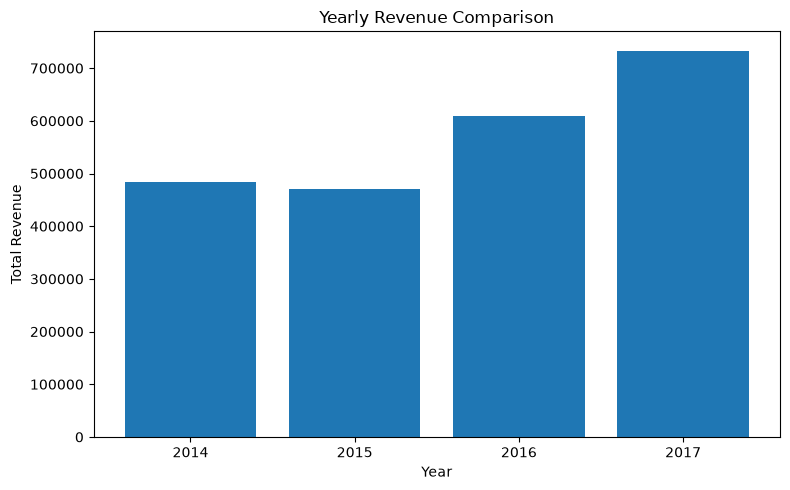

In [64]:
# Yearly Revenue Chart

plt.figure(figsize = (8, 5))
plt.bar(
    yearly_sales["Year"].astype(str),
    yearly_sales["Total_Sales"],
)

plt.title("Yearly Revenue Comparison")
plt.xlabel("Year")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\yearly_revenue.png")
plt.show()

In [28]:
# Product Category Analysis

category_sales = (
    df.groupby("Category")
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum"),
        Total_Quantity = ("Quantity", "sum")
    )
    .reset_index()
)

print(category_sales)

          Category  Total_Sales  Total_Profit  Total_Quantity
0        Furniture  741999.7953    18451.2728            8028
1  Office Supplies  719047.0320   122490.8008           22906
2       Technology  836154.0330   145454.9481            6939


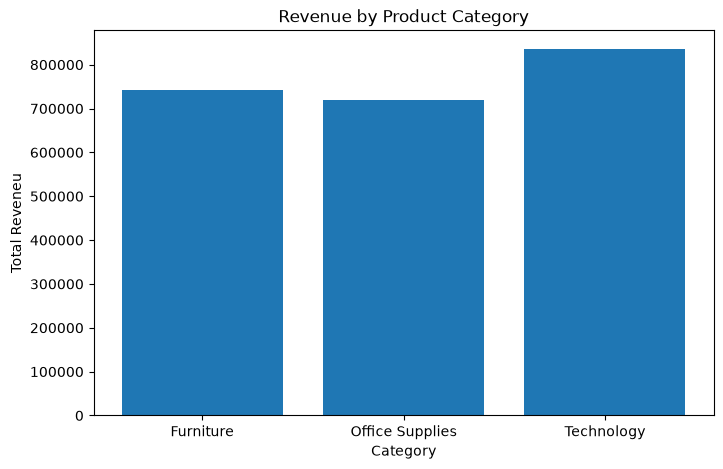

In [63]:
# Revenue by Category

plt.figure(figsize = (8, 5))
plt.bar(
    category_sales["Category"],
    category_sales["Total_Sales"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Reveneu")
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\rev_by_category.png")

plt.show()


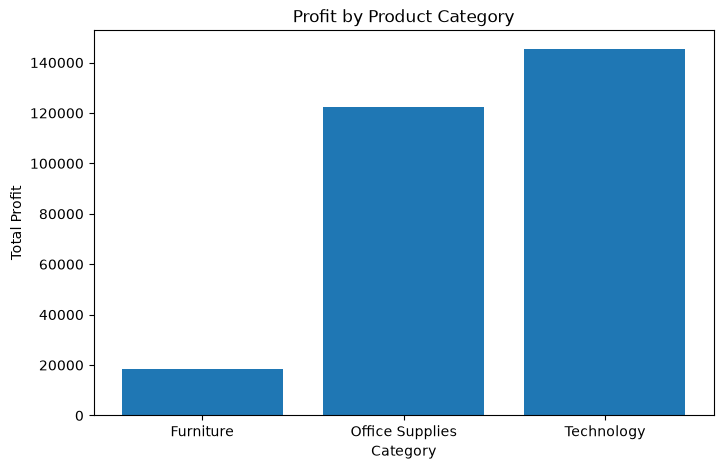

In [62]:
# Profit by Category

plt.figure(figsize = (8, 5))
plt.bar(
    category_sales["Category"],
    category_sales["Total_Profit"]
)

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\profit_by_products.png")
plt.show()

In [35]:
# Regional Sales Analysis

region_sales = (
    df.groupby("Region")
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum"),
        Total_Orders = ("Order ID", "nunique")
    )
    .reset_index()
)
print(region_sales)

    Region  Total_Sales  Total_Profit  Total_Orders
0  Central  501239.8908    39706.3625          1175
1     East  678781.2400    91522.7800          1401
2    South  391721.9050    46749.4303           822
3     West  725457.8245   108418.4489          1611


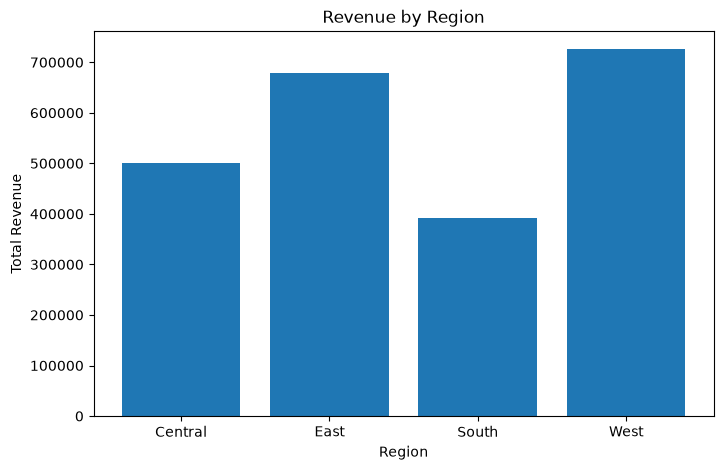

In [61]:
plt.figure(figsize = (8, 5))
plt.bar(
    region_sales["Region"],
    region_sales["Total_Sales"]
)
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\rev_by_religion.png")

plt.show()

In [40]:
# Top 10 Products by Revenue

product_sales = (
    df.groupby(["Product ID", "Product Name"])
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum"),
        Total_Quantity = ("Quantity", "sum")
    )
    .reset_index()
)
top_products = product_sales.sort_values(
    "Total_Sales",
    ascending = False
).head(10)
print(top_products)

           Product ID                                       Product Name  \
1640  TEC-CO-10004722              Canon imageCLASS 2200 Advanced Copier   
787   OFF-BI-10003527  Fellowes PB500 Electric Punch Plastic Comb Bin...   
1669  TEC-MA-10002412  Cisco TelePresence System EX90 Videoconferenci...   
82    FUR-CH-10002024       HON 5400 Series Task Chairs for Big and Tall   
701   OFF-BI-10001359         GBC DocuBind TL300 Electric Binding System   
667   OFF-BI-10000545   GBC Ibimaster 500 Manual ProClick Binding System   
1630  TEC-CO-10001449               Hewlett Packard LaserJet 3310 Copier   
1657  TEC-MA-10001127  HP Designjet T520 Inkjet Large Format Printer ...   
858   OFF-BI-10004995          GBC DocuBind P400 Electric Binding System   
1443  OFF-SU-10000151        High Speed Automatic Electric Letter Opener   

      Total_Sales  Total_Profit  Total_Quantity  
1640    61599.824  2.519993e+04              20  
787     27453.384  7.753039e+03              31  
1669    22638

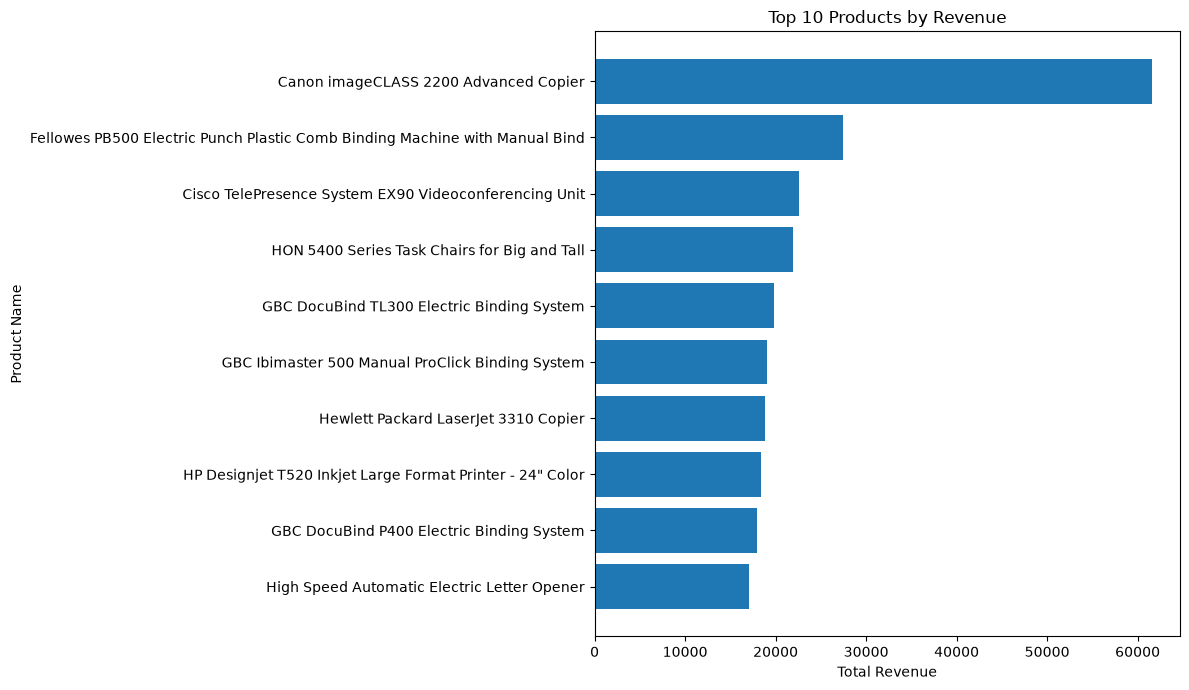

In [60]:
# Top 10 products (chart)

plt.figure(figsize = (12, 7))
plt.barh(
    top_products["Product Name"],
    top_products["Total_Sales"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\top10_products.png")

plt.show()

In [48]:
# Customer Analysis

customer_analysis = (
    df.groupby(["Customer ID", "Customer Name"])
    .agg(
        Total_Revenue = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum"),
        Total_Orders = ("Order ID", "nunique"),
        Total_Quantity = ("Quantity", "sum")
    )
    .reset_index()
)
print("Total Customers: ", df["Customer ID"].nunique())

# Top 10 customers by revenue
top_customers = customer_analysis.sort_values(
    "Total_Revenue",
    ascending = False
).head(10)

print(top_customers)

Total Customers:  793
    Customer ID       Customer Name  Total_Revenue  Total_Profit  \
700    SM-20320         Sean Miller      25043.050    -1980.7393   
741    TC-20980        Tamara Chand      19052.218     8981.3239   
621    RB-19360        Raymond Buch      15117.339     6976.0959   
730    TA-21385        Tom Ashbrook      14595.620     4703.7883   
6      AB-10105       Adrian Barton      14473.571     5444.8055   
434    KL-16645        Ken Lonsdale      14175.229      806.8550   
669    SC-20095        Sanjit Chand      14142.334     5757.4119   
327    HL-15040        Hunter Lopez      12873.298     5622.4292   
683    SE-20110        Sanjit Engle      12209.438     2650.6769   
131    CC-12370  Christopher Conant      12129.072     2177.0493   

     Total_Orders  Total_Quantity  
700             5              50  
741             5              42  
621             6              71  
730             4              36  
6              10              73  
434          

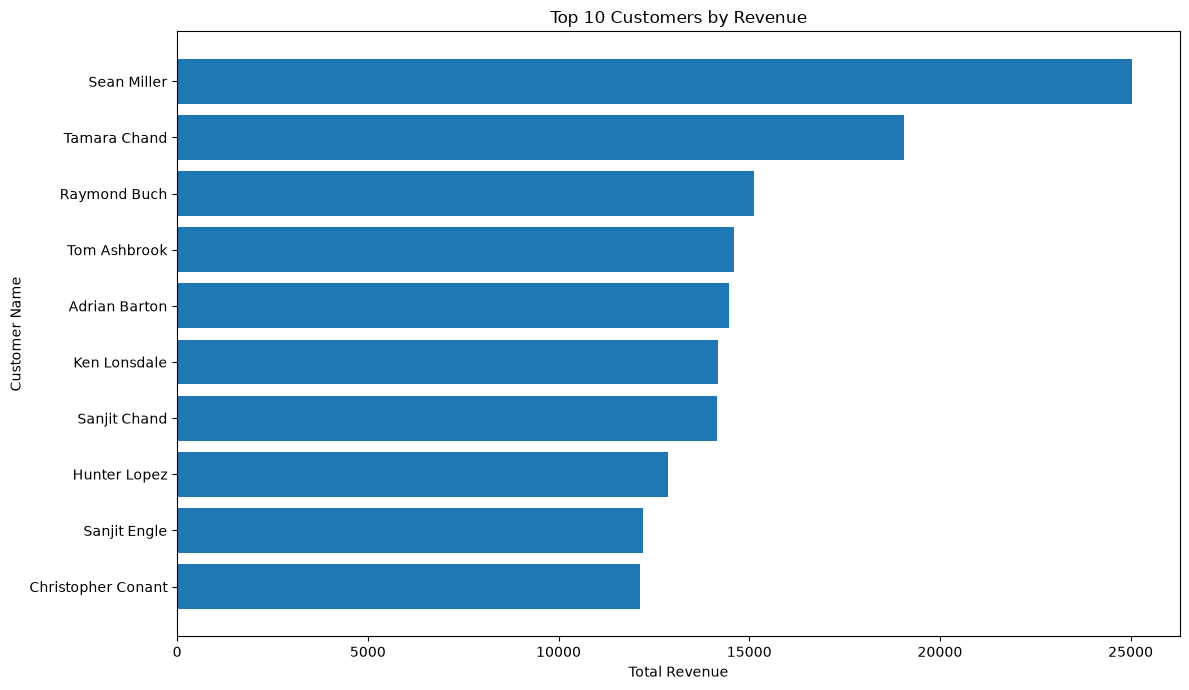

In [59]:
# Top 10 customers by revenue (chart)

plt.figure(figsize = (12, 7))
plt.barh(
    top_customers["Customer Name"],
    top_customers["Total_Revenue"],
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Name")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\top10_customers_by_rev.png")
plt.show()


In [51]:
# Customer Segment Analysis

segment_analysis = (
    df.groupby("Segment")
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum"),
        Total_Customers = ("Customer ID", "nunique"),
        Total_Orders = ("Order ID", "nunique")
    )
    .reset_index()
)
pd.options.display.float_format = '{:,.2f}'.format
print(segment_analysis)

       Segment  Total_Sales  Total_Profit  Total_Customers  Total_Orders
0     Consumer 1,161,401.34    134,119.21              409          2586
1    Corporate   706,146.37     91,979.13              236          1514
2  Home Office   429,653.15     60,298.68              148           909


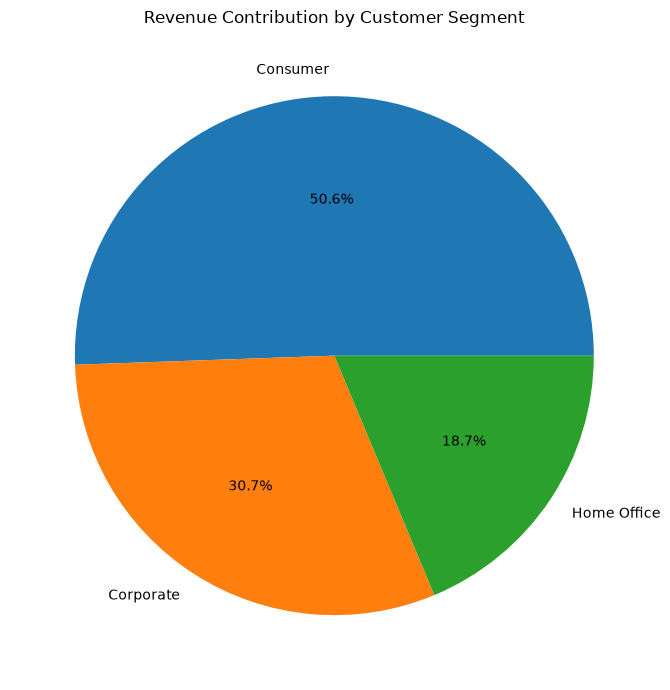

In [58]:
# Revenue contribution by customer segment (chart)

plt.figure(figsize = (7, 7))
plt.pie(
    segment_analysis["Total_Sales"],
    labels  =segment_analysis["Segment"],
    autopct="%1.1f%%",
)
plt.title("Revenue Contribution by Customer Segment")
plt.tight_layout()
plt.savefig(r"D:\Sales & Revenue Analysis\Reports\rev_contribution_customer_seg.png")

plt.show()